# Diagnostics: why the fixed class observables work

This notebook collects the measurements behind the results: whether runs repeat exactly, longer training, which classes are lost, whether the readout can still reach every class, how the client updates behave, more clients, finite measurement shots, how entangled the trained circuits are, and gate and readout noise.

It reads `results/tables/rounds50`, `results/tables/saved`, `results/tables/clients`, the MNIST and PathMNIST folders, the saved models in `results/models`, and the `shots.csv`, `entanglement.csv` and `noise.csv` files written by `experiments/eval_shots.py`, `experiments/eval_entanglement.py` and `experiments/eval_noise.py`. Figures are saved to `results/plots/diagnostics`.

In [23]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

sys.path.insert(0, os.path.abspath(".."))
from models import HybridQNN
from models.hybrid_qnn import class_codes
from data import DATASETS

%matplotlib inline

In [24]:
TABLES_DIR = "../results/tables"
MODELS_DIR = "../results/models"
PLOTS_DIR  = "../results/plots/diagnostics"
os.makedirs(PLOTS_DIR, exist_ok=True)

NAMES = {"qfl_fedavg": "QFL FedAvg", "qfl_fedprox_full": "Full FedProx", "qfl_fco": "Fixed Observables",
         "qfl_pauli": "Pauli Observables", "qfl_frozen": "Random Frozen Readout", "qfl_randcode": "Random Unit Codes",
         "qfl_twin": "Classical Twin", "qfl_twin_fco": "Twin + FCO"}
COLORS = {"qfl_fedavg": "#2a78d6", "qfl_fedprox_full": "#eb6834", "qfl_fco": "#1baf7a", "qfl_pauli": "#e87ba4",
          "qfl_frozen": "#8a8a86", "qfl_randcode": "#6250d6", "qfl_twin": "#eda100", "qfl_twin_fco": "#e34948"}
MARKERS = {"qfl_fedavg": "o", "qfl_fedprox_full": "v", "qfl_fco": "s", "qfl_pauli": "D", "qfl_twin": "^", "qfl_twin_fco": "P"}
MODEL_ARGS = {"qfl_fedavg": {}, "qfl_fedprox_full": {}, "qfl_fco": {"fixed_readout": True}, "qfl_pauli": {"pauli_readout": True},
              "qfl_frozen": {"frozen_readout": True}, "qfl_randcode": {"random_codes": True},
              "qfl_twin": {"twin": True}, "qfl_twin_fco": {"twin": True, "fixed_readout": True}}
FOLDERS = {"fashionmnist": "saved", "mnist": "mnist", "pathmnist": "pathmnist"}
TITLES = {"fashionmnist": "Fashion-MNIST", "mnist": "MNIST", "pathmnist": "PathMNIST"}
FASHION = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK = "#52514e"


def load_runs(kind, folder, split="dirichlet_a0.1", seeds=range(42, 50), clients=10):
    mu = "_mu0.01" if kind == "qfl_fedprox_full" else ""
    runs = {}
    for seed in seeds:
        path = os.path.join(TABLES_DIR, folder, f"{kind}_{split}{mu}_c{clients}_e1_lr0.003_s{seed}.csv")
        if os.path.exists(path):
            runs[seed] = pd.read_csv(path)
    return runs


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", ls="--", alpha=0.4)


def save(fig, name):
    out = os.path.join(PLOTS_DIR, name)
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")

## 1. Every run can be repeated exactly

The same seed gives the same client split, the same starting weights and the same data order. Two groups of runs were repeated: the 50-round runs (their first 20 rounds) and the Fashion-MNIST reruns that saved their models. Both are compared with the original 20-round runs, round by round.

In [25]:
same, total = 0, 0
for folder in ["rounds50", "saved"]:
    for name in sorted(os.listdir(os.path.join(TABLES_DIR, folder))):
        if not name.startswith("qfl_") or not name.endswith(".csv"):
            continue
        repeat = pd.read_csv(os.path.join(TABLES_DIR, folder, name)).iloc[:20]
        original = pd.read_csv(os.path.join(TABLES_DIR, name))
        total += 1
        same += int(repeat["accuracy"].equals(original["accuracy"]) and repeat["loss"].equals(original["loss"]))
print(f"{same} of {total} repeated runs give exactly the same accuracy and loss in every round")

33 of 33 repeated runs give exactly the same accuracy and loss in every round


## 2. More rounds do not save FedAvg

Fashion-MNIST, Dirichlet α = 0.1, seeds 42 to 44, 50 rounds. The dotted line marks the end of the 20-round protocol used everywhere else.

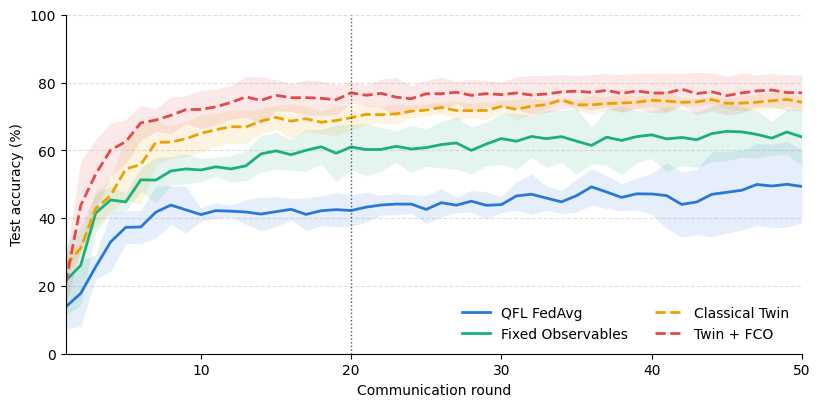

Saved: ../results/plots/diagnostics\rounds50.png


,method,seeds,last-5 at round 20,last-5 at round 50,change
0,QFL FedAvg,3,42.15,49.42,7.27
1,Fixed Observables,3,60.02,64.65,4.64
2,Classical Twin,3,68.97,74.43,5.46
3,Twin + FCO,3,75.70,77.30,1.60


In [26]:
four = ["qfl_fedavg", "qfl_fco", "qfl_twin", "qfl_twin_fco"]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
rows = []
for kind in four:
    runs = load_runs(kind, "rounds50", seeds=range(42, 45))
    acc = np.array([df["accuracy"].values * 100 for df in runs.values()])
    mean, std = acc.mean(axis=0), acc.std(axis=0, ddof=1)
    r = np.arange(1, acc.shape[1] + 1)
    ax.plot(r, mean, color=COLORS[kind], lw=2, ls="--" if "twin" in kind else "-", label=NAMES[kind])
    ax.fill_between(r, mean - std, mean + std, color=COLORS[kind], alpha=0.12, lw=0)
    rows.append({"method": NAMES[kind], "seeds": len(acc), "last-5 at round 20": acc[:, 15:20].mean(),
                 "last-5 at round 50": acc[:, 45:50].mean()})
ax.axvline(20, color=INK, ls=":", lw=1)
ax.set_xlim(1, 50)
ax.set_ylim(0, 100)
ax.set_xlabel("Communication round")
ax.set_ylabel("Test accuracy (%)")
ax.legend(frameon=False, ncol=2, loc="lower right")
style(ax)
save(fig, "rounds50.png")

table = pd.DataFrame(rows)
table["change"] = table["last-5 at round 50"] - table["last-5 at round 20"]
table.round(2)

## 3. Classes that are lost

Per-class test accuracy every round for FedAvg and FCO (Fashion-MNIST, α = 0.1, seed 42, 50 rounds). White rows are classes the global model has lost.

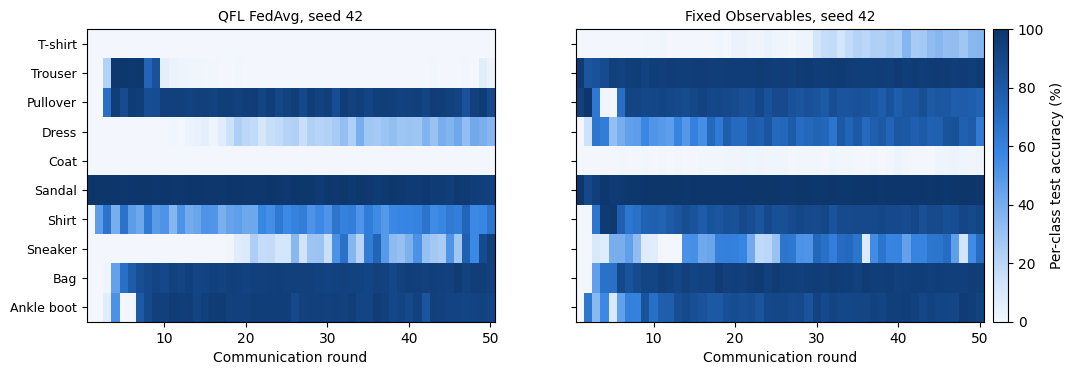

Saved: ../results/plots/diagnostics\class_heatmap.png


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, kind in zip(axes, ["qfl_fedavg", "qfl_fco"]):
    df = load_runs(kind, "rounds50", seeds=[42])[42]
    acc = df[[f"acc_c{c}" for c in range(10)]].values.T * 100
    im = ax.imshow(acc, aspect="auto", cmap=BLUES, vmin=0, vmax=100, extent=[0.5, len(df) + 0.5, 9.5, -0.5])
    ax.set_title(f"{NAMES[kind]}, seed 42", fontsize=10)
    ax.set_xlabel("Communication round")
    ax.set_yticks(range(10))
    ax.set_yticklabels(FASHION, fontsize=9)
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.01)
cb.set_label("Per-class test accuracy (%)")
save(fig, "class_heatmap.png")

Number of lost classes (below 10% accuracy) per round, mean over rounds 11 to 20 and over seeds, on all three datasets at α = 0.1. Fashion-MNIST uses the reruns with per-class accuracy (seeds 42 to 44), MNIST and PathMNIST seeds 42 to 46.

In [28]:
rows = []
for dataset, folder in FOLDERS.items():
    n_classes = DATASETS[dataset][1]
    for kind in four:
        runs = load_runs(kind, folder)
        if not runs:
            continue
        dead = [(df[[f"acc_c{c}" for c in range(n_classes)]].values[10:20] < 0.10).sum(axis=1).mean() for df in runs.values()]
        rows.append({"dataset": TITLES[dataset], "method": NAMES[kind], "seeds": len(dead), "lost classes per round": np.mean(dead)})
pd.DataFrame(rows).pivot(index="method", columns="dataset", values="lost classes per round").reindex(
    [NAMES[k] for k in four])[list(TITLES.values())].round(2)

dataset,Fashion-MNIST,MNIST,PathMNIST
method,,,
QFL FedAvg,4.53,3.54,4.20
Fixed Observables,2.03,1.10,2.80
Classical Twin,1.47,1.36,2.72
Twin + FCO,0.00,0.48,1.94


## 4. Readout collapse: can every class still be predicted?

The readout turns the 4 measured values into class scores. A class is reachable if there is some point in the box of possible readings, [−1, 1]^4, where its score is the highest; a class that is not reachable can never be predicted. We test 400,000 random points of the box.

First the frozen readouts compared in the ablation (seed 42): the random frozen head (FedBABU style), random unit codes, and our fixed class observables.

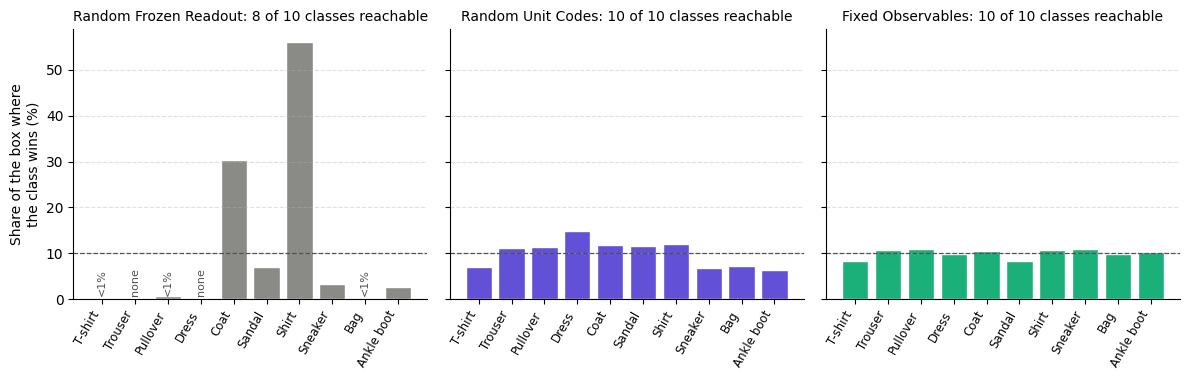

Saved: ../results/plots/diagnostics\readout_shares.png


In [29]:
torch.manual_seed(0)
box = torch.rand(400000, 4) * 2 - 1


def class_shares(weight, bias):
    with torch.no_grad():
        winners = (box @ weight.T + bias).argmax(dim=1)
    return (torch.bincount(winners, minlength=len(weight)).float() / len(box) * 100).numpy()


torch.manual_seed(42)
frozen = HybridQNN(frozen_readout=True).head
torch.manual_seed(42)
random_codes = HybridQNN(random_codes=True).head
panels = [("qfl_frozen", class_shares(frozen.weight, frozen.bias)),
          ("qfl_randcode", class_shares(random_codes.weight, random_codes.bias)),
          ("qfl_fco", class_shares(class_codes(10) * 5, torch.zeros(10)))]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, (kind, shares) in zip(axes, panels):
    ax.bar(range(10), shares, color=COLORS[kind], edgecolor="white")
    for c, share in enumerate(shares):
        if share < 1:
            ax.text(c, 1.2, "none" if share == 0 else "<1%", ha="center", fontsize=8, color=INK, rotation=90)
    ax.axhline(10, color=INK, ls="--", lw=0.9)
    ax.set_title(f"{NAMES[kind]}: {int((shares > 0).sum())} of 10 classes reachable", fontsize=10)
    ax.set_xticks(range(10))
    ax.set_xticklabels(FASHION, rotation=60, ha="right", fontsize=8.5)
    style(ax)
axes[0].set_ylabel("Share of the box where\nthe class wins (%)")
fig.tight_layout()
save(fig, "readout_shares.png")

Then the readouts that were learned during federated training, loaded from the saved models (α = 0.1). FedAvg averages a trainable readout; with fixed class observables every class stays reachable by construction.

In [30]:
rows = []
for dataset, folder in FOLDERS.items():
    in_channels, n_classes = DATASETS[dataset]
    for kind in ["qfl_fedavg", "qfl_twin", "qfl_fco"]:
        reach = []
        for seed in range(42, 50):
            path = os.path.join(MODELS_DIR, folder, f"{kind}_dirichlet_a0.1_c10_e1_lr0.003_s{seed}.pt")
            if not os.path.exists(path):
                continue
            model = HybridQNN(in_channels=in_channels, num_classes=n_classes, **MODEL_ARGS[kind])
            model.load_state_dict(torch.load(path))
            with torch.no_grad():
                reach.append(int((torch.bincount(model.head(box).argmax(dim=1), minlength=n_classes) > 0).sum()))
        if reach:
            rows.append({"dataset": TITLES[dataset], "method": NAMES[kind], "classes": n_classes,
                         "reachable per seed": reach, "mean unreachable": n_classes - np.mean(reach)})
pd.DataFrame(rows)

,dataset,method,classes,reachable per seed,mean unreachable
0,Fashion-MNIST,QFL FedAvg,10,"[8, 9, 8]",1.666667
1,Fashion-MNIST,Classical Twin,10,"[10, 9, 9]",0.666667
2,Fashion-MNIST,Fixed Observables,10,"[10, 10, 10]",0.000000
3,MNIST,QFL FedAvg,10,"[9, 8, 8, 7, 6]",2.400000
4,MNIST,Classical Twin,10,"[9, 9, 9, 9, 9]",1.000000
5,MNIST,Fixed Observables,10,"[10, 10, 10, 10, 10]",0.000000
6,PathMNIST,QFL FedAvg,9,"[7, 7, 7, 6, 9]",1.800000
7,PathMNIST,Classical Twin,9,"[8, 9, 9, 8, 9]",0.400000
8,PathMNIST,Fixed Observables,9,"[9, 9, 9, 9, 9]",0.000000


## 5. How the client updates behave

Mean over rounds 1 to 20 (Fashion-MNIST, α = 0.1, seeds 42 to 44). **drift**: average size of a client's change to a layer, relative to the layer's size. **agreement**: size of the averaged change divided by the average size of the client changes (1 = all clients push the same way, near 0 = their changes cancel in FedAvg). A frozen head has no change, so its numbers are empty.

In [31]:
layers = ["conv1", "conv2", "fc1", "fc2", "vqc", "head"]
rows = []
for kind in four:
    runs = load_runs(kind, "rounds50", seeds=range(42, 45))
    row = {"method": NAMES[kind]}
    for layer in layers:
        row[f"drift {layer}"] = np.mean([df[f"drift_{layer}"].iloc[:20].mean() for df in runs.values()])
        row[f"agree {layer}"] = np.mean([df[f"agree_{layer}"].iloc[:20].mean() for df in runs.values()])
    rows.append(row)
pd.DataFrame(rows).set_index("method").round(3)

,drift conv1,agree conv1,drift conv2,agree conv2,drift fc1,agree fc1,drift fc2,agree fc2,drift vqc,agree vqc,drift head,agree head
method,,,,,,,,,,,,
QFL FedAvg,0.110,0.446,0.280,0.399,0.489,0.370,0.214,0.351,0.023,0.517,0.385,0.379
Fixed Observables,0.101,0.459,0.273,0.399,0.494,0.363,0.230,0.287,0.031,0.344,0.000,NaN
Classical Twin,0.123,0.470,0.286,0.428,0.562,0.392,0.241,0.333,0.150,0.372,0.335,0.385
Twin + FCO,0.112,0.474,0.272,0.418,0.513,0.384,0.216,0.339,0.146,0.318,0.000,NaN


## 6. More clients

Fashion-MNIST, α = 0.1, seeds 42 to 46, with 10, 20 and 50 clients (FedAvg and FCO). Each dot is one seed; the line joins the means.

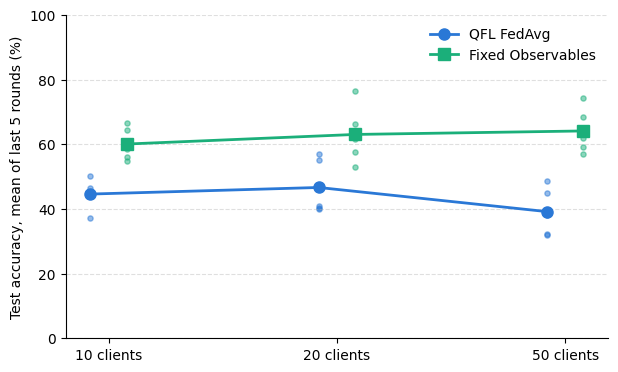

Saved: ../results/plots/diagnostics\client_scale.png


,FedAvg,FCO,gain,better on,p_value
clients,,,,,
10,44.5912,60.0632,15.4720,5/5,0.0089
20,46.6300,63.0284,16.3984,5/5,0.0329
50,39.1640,64.1120,24.9480,5/5,0.0010


In [32]:
rows = []
for clients in [10, 20, 50]:
    folder = "" if clients == 10 else "clients"
    for kind in ["qfl_fedavg", "qfl_fco"]:
        for seed, df in load_runs(kind, folder, seeds=range(42, 47), clients=clients).items():
            rows.append({"clients": clients, "kind": kind, "seed": seed, "last5": df["accuracy"].iloc[-5:].mean() * 100})
scale = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.2))
for kind, offset in [("qfl_fedavg", -0.08), ("qfl_fco", 0.08)]:
    sub = scale[scale["kind"] == kind]
    means = sub.groupby("clients")["last5"].mean()
    x = np.arange(len(means))
    ax.plot(x + offset, means.values, color=COLORS[kind], marker=MARKERS[kind], lw=2, ms=8, label=NAMES[kind])
    for i, clients in enumerate(means.index):
        ax.scatter(np.full(5, i + offset), sub[sub["clients"] == clients]["last5"], color=COLORS[kind], s=14, alpha=0.5)
ax.set_xticks(range(3))
ax.set_xticklabels(["10 clients", "20 clients", "50 clients"])
ax.set_ylim(0, 100)
ax.set_ylabel("Test accuracy, mean of last 5 rounds (%)")
ax.legend(frameon=False)
style(ax)
save(fig, "client_scale.png")

table = scale.pivot_table(index=["clients", "seed"], columns="kind", values="last5")
gain = (table["qfl_fco"] - table["qfl_fedavg"]).groupby(level="clients")
pd.DataFrame({"FedAvg": table["qfl_fedavg"].groupby(level="clients").mean(), "FCO": table["qfl_fco"].groupby(level="clients").mean(),
              "gain": gain.mean(), "better on": gain.apply(lambda d: f"{(d > 0).sum()}/{len(d)}"),
              "p_value": gain.apply(lambda d: stats.ttest_1samp(d, 0).pvalue)}).round(4)

## 7. Finite measurement shots

On quantum hardware each reading is estimated from a finite number of shots: all qubits are measured, and every Z (and Z_i Z_j) reading is computed from the same measured bitstrings. `experiments/eval_shots.py` does exactly this with the saved models (trained without noise) and writes `shots.csv`. Mean test accuracy over seeds at α = 0.1; "exact" is the noiseless value. Datasets without a `shots.csv` yet are skipped.

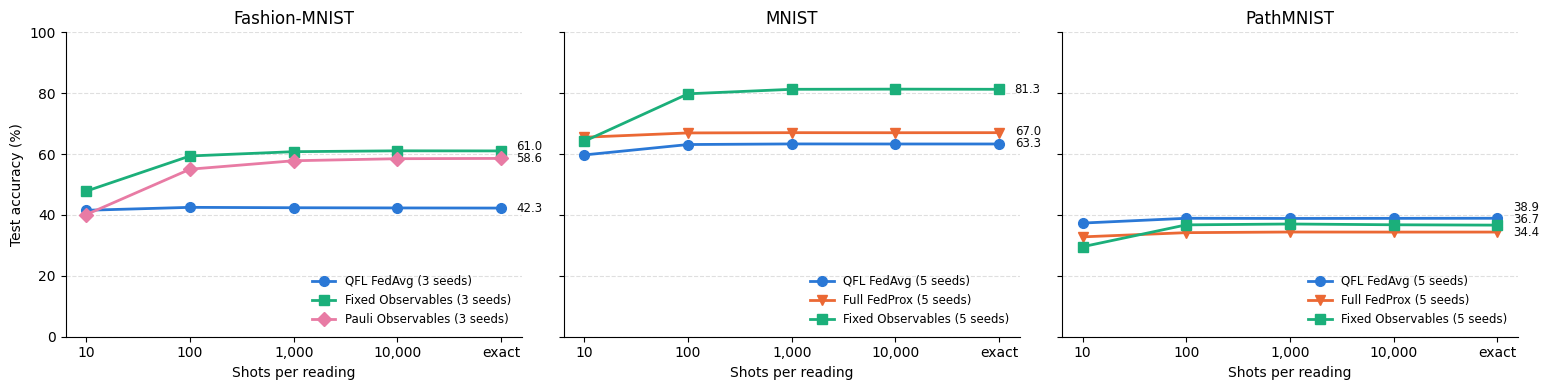

Saved: ../results/plots/diagnostics\shot_noise.png


shots                              10    100   1000  10000  exact
dataset       kind                                               
Fashion-MNIST qfl_fco           47.85  59.38  60.79  61.07  61.04
              qfl_fedavg        41.54  42.50  42.38  42.31  42.26
              qfl_frozen        28.26  28.71  28.67  28.67  28.66
              qfl_pauli         40.14  55.04  57.81  58.48  58.58
              qfl_randcode      44.46  55.26  57.00  57.32  57.30
MNIST         qfl_fco           64.24  79.81  81.28  81.34  81.29
              qfl_fedavg        59.73  63.14  63.34  63.32  63.32
              qfl_fedprox_full  65.54  66.95  67.04  67.02  67.04
PathMNIST     qfl_fco           29.56  36.74  37.03  36.78  36.66
              qfl_fedavg        37.34  38.91  38.86  38.89  38.92
              qfl_fedprox_full  32.80  34.19  34.40  34.37  34.38

In [33]:
shot_tables = []
for dataset, folder in FOLDERS.items():
    path = os.path.join(TABLES_DIR, folder, "shots.csv")
    if os.path.exists(path):
        df = pd.read_csv(path)
        df["dataset"] = TITLES[dataset]
        shot_tables.append(df[(df["partition"] == "dirichlet") & (df["alpha"] == 0.1) & (df["clients"] == 10)])

if not shot_tables:
    print("No shots.csv found yet: run experiments/eval_shots.py first")
else:
    shots = pd.concat(shot_tables)
    levels = sorted(shots["shots"].unique())
    datasets = list(dict.fromkeys(shots["dataset"]))
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.2 * len(datasets), 4), sharey=True, squeeze=False)
    for ax, dataset in zip(axes[0], datasets):
        sub = shots[shots["dataset"] == dataset]
        ends = []
        for kind in ["qfl_fedavg", "qfl_fedprox_full", "qfl_fco", "qfl_pauli"]:
            k = sub[sub["kind"] == kind]
            if k.empty:
                continue
            means = [k[k["shots"] == s]["accuracy"].mean() * 100 for s in levels] + [k.groupby("seed")["exact_accuracy"].first().mean() * 100]
            n = k["seed"].nunique()
            ax.plot(range(len(means)), means, color=COLORS[kind], marker=MARKERS[kind], lw=2, ms=7, label=f"{NAMES[kind]} ({n} seed{'s' if n > 1 else ''})")
            ends.append(means[-1])
        # value labels at the right end, moved apart so they never overlap
        placed = sorted(ends)
        for i in range(1, len(placed)):
            placed[i] = max(placed[i], placed[i - 1] + 4)
        for value, y in zip(sorted(ends), placed):
            ax.text(len(levels) + 0.15, y, f"{value:.1f}", va="center", fontsize=8.5, color="#0b0b0b")
        ax.set_xticks(range(len(levels) + 1))
        ax.set_xticklabels([f"{s:,}" for s in levels] + ["exact"])
        ax.set_xlabel("Shots per reading")
        ax.set_title(dataset)
        ax.set_ylim(0, 100)
        style(ax)
        ax.legend(frameon=False, fontsize=8.5, loc="lower right")
    axes[0][0].set_ylabel("Test accuracy (%)")
    fig.tight_layout()
    save(fig, "shot_noise.png")

    summary = shots.groupby(["dataset", "kind", "shots"])["accuracy"].mean().unstack("shots") * 100
    summary["exact"] = shots.groupby(["dataset", "kind"])["exact_accuracy"].mean() * 100
    display(summary.round(2))

## 8. Entanglement and superposition in the trained circuits

`experiments/eval_entanglement.py` computes the circuit state |ψ(x)⟩ for every test image, once with the starting weights of the run (same seed, before training) and once with the trained model, and writes `entanglement.csv`. Averages over the test images:

- **Meyer-Wallach entanglement Q:** 0 when the 4 qubits are in a product state (no entanglement), at most 1. For a pure state Q = 1 − mean squared Bloch vector length of the single qubits.
- **Measurement entropy:** Shannon entropy in bits of the 16 measurement outcomes. 0 means the state is one bitstring, 4 means all 16 outcomes are equally likely, so it shows how much superposition is left.
- **Connected ZZ correlation:** mean of |⟨Z_iZ_j⟩ − ⟨Z_i⟩⟨Z_j⟩| over the 6 pairs. It is 0 for every pair in a product state.
- **Mean squared Z reading:** what the readout actually sees. It can never be larger than 1 − Q, so a more entangled state gives smaller readings.

Mean over seeds at α = 0.1.

In [34]:
ent_tables = []
for dataset, folder in FOLDERS.items():
    path = os.path.join(TABLES_DIR, folder, "entanglement.csv")
    if os.path.exists(path):
        df = pd.read_csv(path)
        df["dataset"] = TITLES[dataset]
        ent_tables.append(df)

if not ent_tables:
    print("No entanglement.csv found yet: run experiments/eval_entanglement.py first")
else:
    ent = pd.concat(ent_tables)
    print("Mean squared Z reading <= 1 - Q on every model:", bool((ent["z_norm"] <= 1 - ent["meyer_wallach"] + 1e-9).all()))
    ent01 = ent[(ent["partition"] == "dirichlet") & (ent["alpha"] == 0.1) & (ent["clients"] == 10)]
    start = ent01[ent01["stage"] == "init"].groupby(["dataset", "kind"])["meyer_wallach"].mean()
    trained = ent01[ent01["stage"] == "trained"].groupby(["dataset", "kind"])
    table = pd.DataFrame({"seeds": trained["seed"].nunique(), "Q at start": start, "Q trained": trained["meyer_wallach"].mean(),
                          "entropy (bits)": trained["entropy"].mean(), "ZZ correlation": trained["zz_connected"].mean(),
                          "mean Z^2": trained["z_norm"].mean(), "accuracy (%)": trained["accuracy"].mean() * 100})
    display(table.round(3))

Mean squared Z reading <= 1 - Q on every model: True


seeds  Q at start  Q trained  entropy (bits)  \
dataset       kind                                                             
Fashion-MNIST qfl_fco               3       0.892      0.759           3.076   
              qfl_fedavg            3       0.892      0.461           1.138   
              qfl_frozen            3       0.892      0.350           0.852   
              qfl_pauli             3       0.892      0.813           3.027   
              qfl_randcode          3       0.892      0.732           2.700   
MNIST         qfl_fco               5       0.894      0.716           2.807   
              qfl_fedavg            5       0.894      0.474           1.214   
              qfl_fedprox_full      5       0.894      0.365           0.901   
PathMNIST     qfl_fco               5       0.913      0.817           3.088   
              qfl_fedavg            5       0.913      0.614           1.769   
              qfl_fedprox_full      5       0.913      0.645           1.779   

                                ZZ correlation  mean Z^2  accuracy (%)  
dataset       kind                                                      
Fashion-MNIST qfl_fco                    0.110     0.165        61.040  
              qfl_fedavg                 0.233     0.514        42.263  
              qfl_frozen                 0.175     0.639        28.663  
              qfl_pauli                  0.226     0.077        58.580  
              qfl_randcode               0.199     0.195        57.297  
MNIST         qfl_fco                    0.139     0.201        81.286  
              qfl_fedavg                 0.220     0.503        63.320  
              qfl_fedprox_full           0.181     0.624        67.042  
PathMNIST     qfl_fco                    0.162     0.093        36.660  
              qfl_fedavg                 0.259     0.334        38.916  
              qfl_fedprox_full           0.275     0.304        34.384

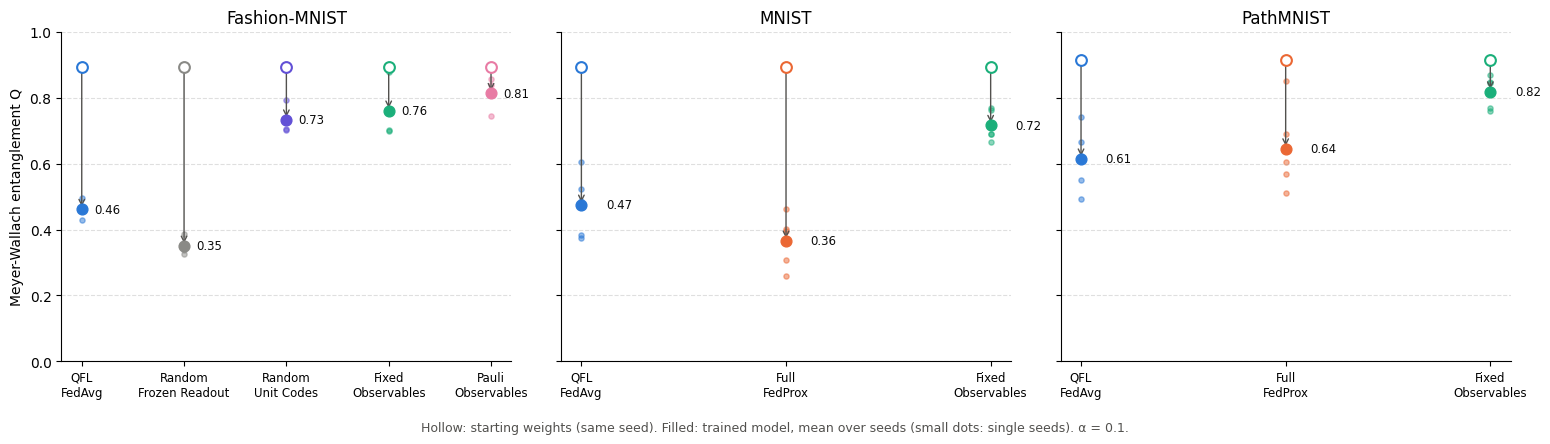

Saved: ../results/plots/diagnostics\entanglement.png


In [35]:
if ent_tables:
    datasets = list(dict.fromkeys(ent01["dataset"]))
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.2 * len(datasets), 4.2), sharey=True, squeeze=False)
    for ax, dataset in zip(axes[0], datasets):
        sub = ent01[ent01["dataset"] == dataset]
        kinds = [k for k in ["qfl_fedavg", "qfl_fedprox_full", "qfl_frozen", "qfl_randcode", "qfl_fco", "qfl_pauli"] if k in set(sub["kind"])]
        for i, kind in enumerate(kinds):
            k = sub[sub["kind"] == kind]
            before = k[k["stage"] == "init"]["meyer_wallach"]
            after = k[k["stage"] == "trained"]["meyer_wallach"]
            ax.scatter(np.full(len(after), i), after, color=COLORS[kind], s=14, alpha=0.5)
            ax.annotate("", xy=(i, after.mean()), xytext=(i, before.mean()),
                        arrowprops=dict(arrowstyle="->", color=INK, lw=1))
            ax.scatter(i, before.mean(), facecolors="white", edgecolors=COLORS[kind], s=60, lw=1.5, zorder=3)
            ax.scatter(i, after.mean(), color=COLORS[kind], s=60, zorder=3)
            ax.text(i + 0.12, after.mean(), f"{after.mean():.2f}", va="center", fontsize=8.5, color="#0b0b0b")
        ax.set_xticks(range(len(kinds)))
        ax.set_xticklabels([NAMES[k].replace(" ", "\n", 1) for k in kinds], fontsize=8.5)
        ax.set_title(dataset)
        ax.set_ylim(0, 1)
        style(ax)
    axes[0][0].set_ylabel("Meyer-Wallach entanglement Q")
    fig.text(0.5, -0.04, "Hollow: starting weights (same seed). Filled: trained model, mean over seeds (small dots: single seeds). α = 0.1.",
             ha="center", fontsize=9, color=INK)
    fig.tight_layout()
    save(fig, "entanglement.png")

## 9. Gate and readout noise

`experiments/eval_noise.py` runs the saved models (trained without noise) on PennyLane's density-matrix simulator `default.mixed` and writes `noise.csv`:

- **Gate noise p:** a depolarizing channel with probability p after every gate, on each qubit the gate acts on (4 RX of the encoding, 8 Rot and 8 CNOT, so 28 channels).
- **Readout error q:** every measured bit is reported flipped with probability q.
- Expectations are exact (no shots), so this is separate from the shot noise of section 7. The fidelity ⟨ψ|ρ|ψ⟩ shows how far the noisy state ρ is from the noiseless state |ψ⟩.

Why readout error cannot change the fixed class observables: flipping every bit with probability q multiplies every Z reading by (1 − 2q). FCO scores every class with a fixed linear map and no bias, so all scores shrink by the same factor and the largest stays the largest. A trained readout has biases, so shrinking the readings can change its prediction. Mean over seeds at α = 0.1.

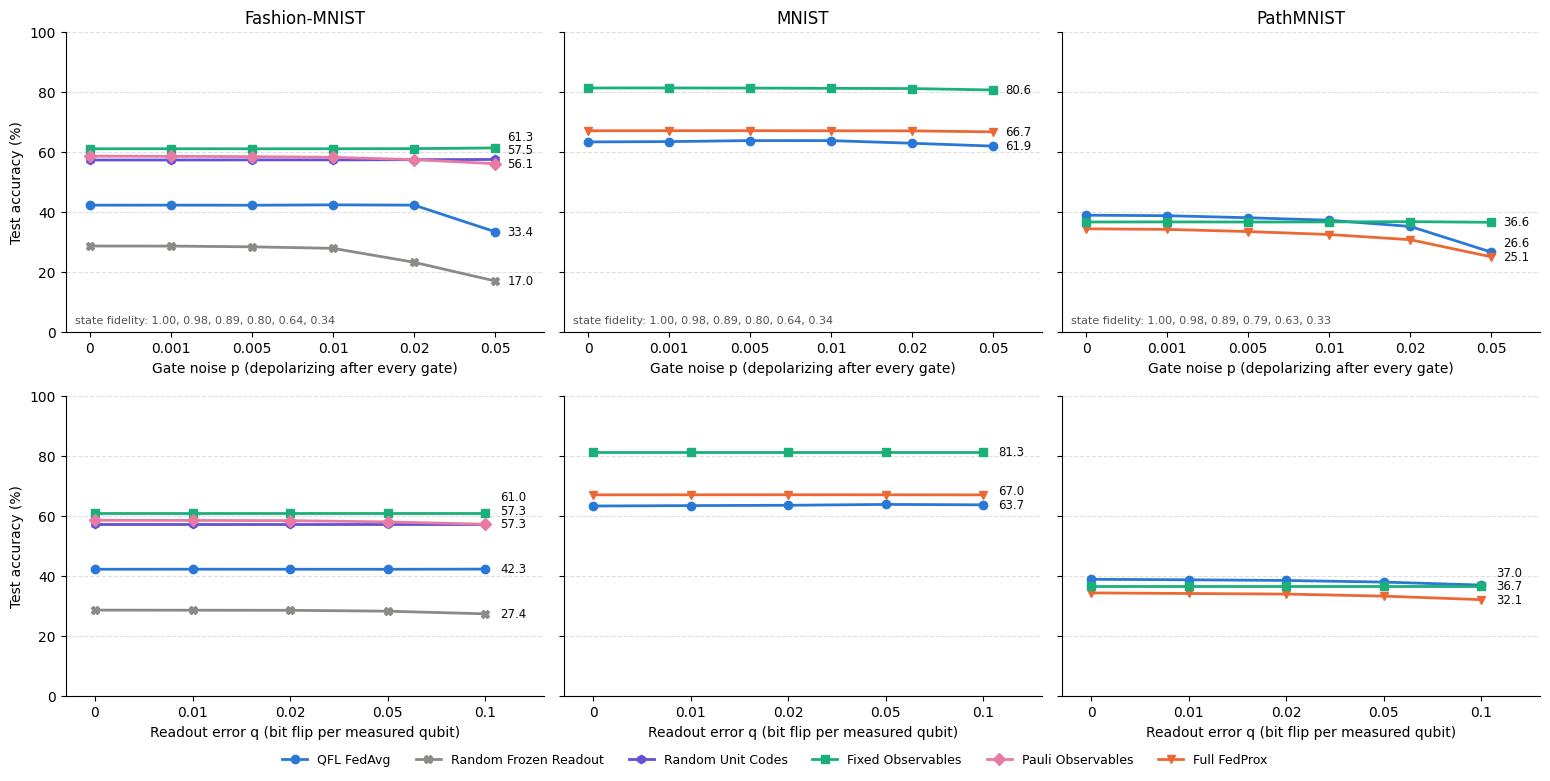

Saved: ../results/plots/diagnostics\gate_readout_noise.png


In [36]:
noise_tables = []
for dataset, folder in FOLDERS.items():
    path = os.path.join(TABLES_DIR, folder, "noise.csv")
    if os.path.exists(path):
        df = pd.read_csv(path)
        df["dataset"] = TITLES[dataset]
        noise_tables.append(df[(df["partition"] == "dirichlet") & (df["alpha"] == 0.1) & (df["clients"] == 10)])

if not noise_tables:
    print("No noise.csv found yet: run experiments/eval_noise.py first")
else:
    noise = pd.concat(noise_tables)
    datasets = list(dict.fromkeys(noise["dataset"]))
    markers = {**MARKERS, "qfl_frozen": "X", "qfl_randcode": "h"}
    fig, axes = plt.subplots(2, len(datasets), figsize=(5.2 * len(datasets), 7.6), sharey="row", squeeze=False)
    for row, (column, other, label) in enumerate([("gate_noise", "readout_error", "Gate noise p (depolarizing after every gate)"),
                                                   ("readout_error", "gate_noise", "Readout error q (bit flip per measured qubit)")]):
        for ax, dataset in zip(axes[row], datasets):
            sub = noise[(noise["dataset"] == dataset) & (noise[other] == 0)]
            levels = sorted(sub[column].unique())
            ends = []
            for kind in ["qfl_fedavg", "qfl_fedprox_full", "qfl_frozen", "qfl_randcode", "qfl_fco", "qfl_pauli"]:
                k = sub[sub["kind"] == kind]
                if k.empty:
                    continue
                means = [k[k[column] == level]["accuracy"].mean() * 100 for level in levels]
                ax.plot(range(len(levels)), means, color=COLORS[kind], marker=markers[kind], lw=2, ms=6, label=NAMES[kind])
                ends.append(means[-1])
            # value labels at the right end, moved apart so they never overlap
            placed = sorted(ends)
            for i in range(1, len(placed)):
                placed[i] = max(placed[i], placed[i - 1] + 4.5)
            for value, y in zip(sorted(ends), placed):
                ax.text(len(levels) - 0.85, y, f"{value:.1f}", va="center", fontsize=8.5, color="#0b0b0b")
            ax.set_xticks(range(len(levels)))
            ax.set_xticklabels([f"{level:g}" for level in levels])
            ax.set_xlim(-0.3, len(levels) - 0.4)
            ax.set_xlabel(label)
            ax.set_ylim(0, 100)
            if row == 0:
                ax.set_title(dataset)
                fidelity = sub[sub["kind"] == "qfl_fco"].groupby(column)["fidelity"].mean()
                ax.text(0.02, 0.03, "state fidelity: " + ", ".join(f"{f:.2f}" for f in fidelity), transform=ax.transAxes,
                        fontsize=8, color=INK)
            style(ax)
        axes[row][0].set_ylabel("Test accuracy (%)")
    handles = {}
    for ax in axes.flat:
        for handle, name in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(name, handle)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=len(handles), frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout()
    save(fig, "gate_readout_noise.png")

In [37]:
if noise_tables:
    exact = noise[(noise["gate_noise"] == 0) & (noise["readout_error"] == 0)].groupby(["dataset", "kind"])["accuracy"].mean() * 100
    change = {"exact (%)": exact}
    for p in [0.01, 0.05]:
        change[f"gate p={p}"] = noise[(noise["gate_noise"] == p) & (noise["readout_error"] == 0)].groupby(["dataset", "kind"])["accuracy"].mean() * 100 - exact
    for q in [0.05, 0.1]:
        change[f"readout q={q}"] = noise[(noise["gate_noise"] == 0) & (noise["readout_error"] == q)].groupby(["dataset", "kind"])["accuracy"].mean() * 100 - exact
    change["both p=0.01, q=0.02"] = noise[(noise["gate_noise"] == 0.01) & (noise["readout_error"] == 0.02)].groupby(["dataset", "kind"])["accuracy"].mean() * 100 - exact
    print("Change in test accuracy (points) from the noiseless value:")
    display(pd.DataFrame(change).round(2))
    print("Mean state fidelity for each gate noise level:")
    display(noise.groupby(["dataset", "gate_noise"])["fidelity"].mean().unstack("gate_noise").round(3))

Change in test accuracy (points) from the noiseless value:


exact (%)  gate p=0.01  gate p=0.05  \
dataset       kind                                                    
Fashion-MNIST qfl_fco               61.04         0.01         0.28   
              qfl_fedavg            42.26         0.11        -8.86   
              qfl_frozen            28.66        -0.77       -11.65   
              qfl_pauli             58.58        -0.38        -2.50   
              qfl_randcode          57.30         0.04         0.19   
MNIST         qfl_fco               81.29        -0.11        -0.67   
              qfl_fedavg            63.32         0.44        -1.40   
              qfl_fedprox_full      67.04        -0.01        -0.37   
PathMNIST     qfl_fco               36.66         0.02        -0.09   
              qfl_fedavg            38.92        -1.67       -12.30   
              qfl_fedprox_full      34.38        -1.89        -9.33   

                                readout q=0.05  readout q=0.1  \
dataset       kind                                              
Fashion-MNIST qfl_fco                     0.00           0.00   
              qfl_fedavg                 -0.01           0.05   
              qfl_frozen                 -0.36          -1.24   
              qfl_pauli                  -0.55          -1.32   
              qfl_randcode                0.00           0.00   
MNIST         qfl_fco                     0.00           0.00   
              qfl_fedavg                  0.53           0.40   
              qfl_fedprox_full            0.02          -0.01   
PathMNIST     qfl_fco                     0.00           0.00   
              qfl_fedavg                 -0.92          -1.92   
              qfl_fedprox_full           -1.07          -2.25   

                                both p=0.01, q=0.02  
dataset       kind                                   
Fashion-MNIST qfl_fco                          0.01  
              qfl_fedavg                       0.11  
              qfl_frozen                      -1.27  
              qfl_pauli                       -0.72  
              qfl_randcode                     0.04  
MNIST         qfl_fco                         -0.11  
              qfl_fedavg                       0.28  
              qfl_fedprox_full                 0.00  
PathMNIST     qfl_fco                          0.02  
              qfl_fedavg                      -2.01  
              qfl_fedprox_full                -2.29

Mean state fidelity for each gate noise level:


gate_noise,0.000,0.001,0.005,0.010,0.020,0.050
dataset,,,,,,
Fashion-MNIST,1.0,0.978,0.895,0.802,0.645,0.348
MNIST,1.0,0.979,0.897,0.806,0.652,0.357
PathMNIST,1.0,0.977,0.892,0.797,0.638,0.339
